In [1]:
import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "online_retail_II.xlsx"

df_customers = pd.concat(
    [
        pd.read_excel(DATA_PATH, sheet_name="Year 2009-2010"),
        pd.read_excel(DATA_PATH, sheet_name="Year 2010-2011")
    ],
    ignore_index=True
)

print("Dataset shape:", df_customers.shape)
print("Columns:", df_customers.columns.tolist())
print("Missing Customer IDs:", df_customers["Customer ID"].isna().sum())
print(df_customers.head())

Dataset shape: (1067371, 8)
Columns: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']
Missing Customer IDs: 243007
  Invoice StockCode                          Description  Quantity  \
0  489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12   
1  489434    79323P                   PINK CHERRY LIGHTS        12   
2  489434    79323W                  WHITE CHERRY LIGHTS        12   
3  489434     22041         RECORD FRAME 7" SINGLE SIZE         48   
4  489434     21232       STRAWBERRY CERAMIC TRINKET BOX        24   

          InvoiceDate  Price  Customer ID         Country  
0 2009-12-01 07:45:00   6.95      13085.0  United Kingdom  
1 2009-12-01 07:45:00   6.75      13085.0  United Kingdom  
2 2009-12-01 07:45:00   6.75      13085.0  United Kingdom  
3 2009-12-01 07:45:00   2.10      13085.0  United Kingdom  
4 2009-12-01 07:45:00   1.25      13085.0  United Kingdom  


In [2]:
# Convert columns to correct data types
df_customers["InvoiceDate"] = pd.to_datetime(
    df_customers["InvoiceDate"],
    errors="coerce"
)

# Remove rows without customer IDs
# Exclude cancelled invoices (invoice numbers starting with C)
# Keep only positive quantity and price
customer_df = df_customers.dropna(
    subset=["Customer ID", "InvoiceDate"]
).copy()

customer_df["Invoice"] = customer_df["Invoice"].astype(str)

customer_df = customer_df[
    (~customer_df["Invoice"].str.startswith("C")) &
    (customer_df["Quantity"] > 0) &
    (customer_df["Price"] > 0)
].copy()

# Calculate revenue for each transaction line
customer_df["Revenue"] = (
    customer_df["Quantity"] * customer_df["Price"]
)

print("Clean customer data shape:", customer_df.shape)
print("Unique customers:", customer_df["Customer ID"].nunique())
print("Date range:", customer_df["InvoiceDate"].min(),
      "to", customer_df["InvoiceDate"].max())
print("Missing values:")
print(customer_df[["Customer ID", "InvoiceDate", "Revenue"]].isna().sum())

Clean customer data shape: (805549, 9)
Unique customers: 5878
Date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00
Missing values:
Customer ID    0
InvoiceDate    0
Revenue        0
dtype: int64


In [3]:
# Reference date: one day after the latest transaction
reference_date = customer_df["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)

rfm = customer_df.groupby("Customer ID").agg(
    Recency=("InvoiceDate", lambda x: (reference_date - x.max()).days),
    Frequency=("Invoice", "nunique"),
    Monetary=("Revenue", "sum")
).reset_index()

rfm.columns = ["CustomerID", "Recency", "Frequency", "Monetary"]

print("RFM shape:", rfm.shape)
print("\nFirst 5 customers:")
print(rfm.head())

print("\nRFM summary:")
print(rfm[["Recency", "Frequency", "Monetary"]].describe().round(2))

RFM shape: (5878, 4)

First 5 customers:
   CustomerID  Recency  Frequency  Monetary
0     12346.0      325         12  77556.46
1     12347.0        2          8   5633.32
2     12348.0       75          5   2019.40
3     12349.0       18          4   4428.69
4     12350.0      310          1    334.40

RFM summary:
       Recency  Frequency   Monetary
count  5878.00    5878.00    5878.00
mean    200.87       6.29    3018.62
std     209.35      13.01   14737.73
min       0.00       1.00       2.95
25%      25.00       1.00     348.76
50%      95.00       3.00     898.92
75%     379.00       7.00    2307.09
max     738.00     398.00  608821.65


In [4]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Copy RFM features
rfm_model = rfm[["Recency", "Frequency", "Monetary"]].copy()

# Reduce skew from very large customer spending values
rfm_model["Frequency"] = np.log1p(rfm_model["Frequency"])
rfm_model["Monetary"] = np.log1p(rfm_model["Monetary"])

# Scale all three features
scaler_rfm = StandardScaler()
X_rfm = scaler_rfm.fit_transform(rfm_model)

# Create 6 customer segments
kmeans = KMeans(
    n_clusters=6,
    random_state=42,
    n_init=10
)

rfm["Segment"] = kmeans.fit_predict(X_rfm)

print("Customer count:", len(rfm))
print("\nCustomers per segment:")
print(rfm["Segment"].value_counts().sort_index())

print("\nSegment averages:")
print(
    rfm.groupby("Segment")[
        ["Recency", "Frequency", "Monetary"]
    ].mean().round(2)
)

Customer count: 5878

Customers per segment:
Segment
0    1029
1     981
2    1374
3    1199
4     433
5     862
Name: count, dtype: int64

Segment averages:
         Recency  Frequency  Monetary
Segment                              
0         531.00       1.19    251.29
1         118.81       1.41    298.12
2          68.25       3.72   1165.82
3          56.14       9.59   3982.74
4          30.49      34.48  22406.00
5         398.45       3.27   1291.71


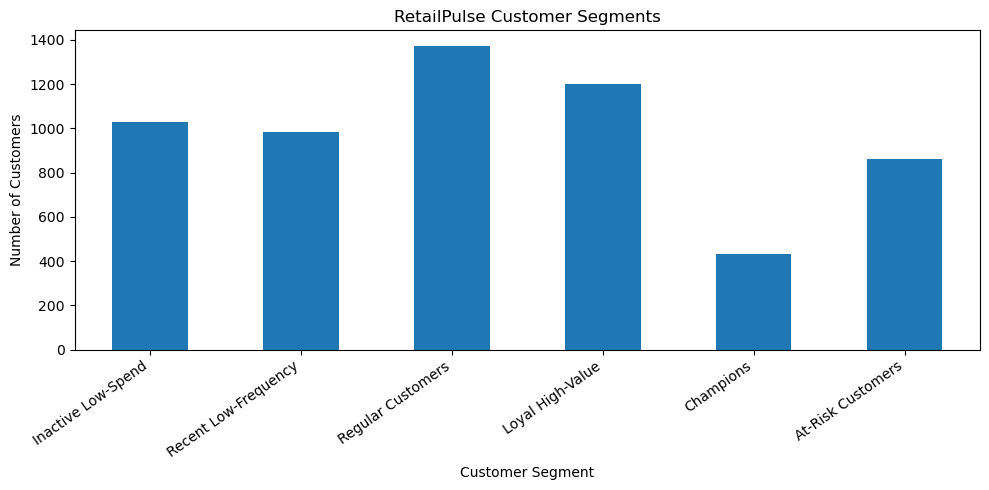

Customer segments saved: c:\Users\mukes\Downloads\OneDrive\Documents\RetailPulse\data\processed\customer_segments.csv
Segment summary saved: c:\Users\mukes\Downloads\OneDrive\Documents\RetailPulse\reports\customer_segment_summary.csv
 Segment         Segment_Name  Customer_Count  Avg_Recency  Avg_Frequency  Avg_Monetary
       0   Inactive Low-Spend            1029       531.00           1.19        251.29
       1 Recent Low-Frequency             981       118.81           1.41        298.12
       2    Regular Customers            1374        68.25           3.72       1165.82
       3     Loyal High-Value            1199        56.14           9.59       3982.74
       4            Champions             433        30.49          34.48      22406.00
       5    At-Risk Customers             862       398.45           3.27       1291.71


In [5]:
# Give meaningful names to the 6 clusters
segment_names = {
    0: "Inactive Low-Spend",
    1: "Recent Low-Frequency",
    2: "Regular Customers",
    3: "Loyal High-Value",
    4: "Champions",
    5: "At-Risk Customers"
}

rfm["Segment_Name"] = rfm["Segment"].map(segment_names)

# Create output folder
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
OUTPUT_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# Save customer-level segments
rfm.to_csv(
    OUTPUT_DIR / "customer_segments.csv",
    index=False
)

# Save segment summary
segment_summary = (
    rfm.groupby(["Segment", "Segment_Name"])
    .agg(
        Customer_Count=("CustomerID", "count"),
        Avg_Recency=("Recency", "mean"),
        Avg_Frequency=("Frequency", "mean"),
        Avg_Monetary=("Monetary", "mean")
    )
    .reset_index()
    .round(2)
)

segment_summary.to_csv(
    REPORTS_DIR / "customer_segment_summary.csv",
    index=False
)

# Plot customer count per segment
import matplotlib.pyplot as plt

segment_summary.plot(
    x="Segment_Name",
    y="Customer_Count",
    kind="bar",
    legend=False,
    figsize=(10, 5)
)

plt.title("RetailPulse Customer Segments")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

print("Customer segments saved:", OUTPUT_DIR / "customer_segments.csv")
print("Segment summary saved:", REPORTS_DIR / "customer_segment_summary.csv")
print(segment_summary.to_string(index=False))

In [6]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd().parent

segments_path = PROJECT_ROOT / "data" / "processed" / "customer_segments.csv"
summary_path = PROJECT_ROOT / "reports" / "customer_segment_summary.csv"

segments = pd.read_csv(segments_path)
summary = pd.read_csv(summary_path)

print("Customer segments:", segments.shape)
print("Segment summary:", summary.shape)
print("Missing values in customer segments:", segments.isna().sum().sum())
print("Total customers across segments:", summary["Customer_Count"].sum())
print("\nSegment names:")
print(summary["Segment_Name"].tolist())

Customer segments: (5878, 6)
Segment summary: (6, 6)
Missing values in customer segments: 0
Total customers across segments: 5878

Segment names:
['Inactive Low-Spend', 'Recent Low-Frequency', 'Regular Customers', 'Loyal High-Value', 'Champions', 'At-Risk Customers']
